In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score, RocCurveDisplay)

# Import your model here
import torch, torch.nn as nn

# Import train_test_split, seaborn, matplotlib
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
#Change to your model's name (used in graphs)
MODEL_NAME = "Multi-Layer Perceptron"

# Read dataset
df = pd.read_csv("../../data/CleanedLifeInsurance.csv")

# Define features and target
numeric_features = ["ENTRY AGE", "Policy Year", "BENEFIT", "Premium", "SUBSTANDARD RISK"]
categorical_features = ["PAYMENT MODE"]

X = df[numeric_features + categorical_features]
y = df["is_lapse"]

# Split data into train and test sets (keep random_state = 42 to ensure you get the same data splits every time.)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
# Preprocess features
# numeric: fill missing values (Premium, BENEFIT) with the median, add a column flagging
# which values were missing, then scale. Scaling doesn't matter for tree models but doesn't hurt.
# categorical: one-hot encode PAYMENT MODE into 0/1 columns.

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

Xt = torch.tensor(X_train, dtype=torch.float32)
yt = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
Xv = torch.tensor(X_test, dtype=torch.float32)

In [20]:
model = nn.Sequential(
    nn.Linear(Xt.shape[1], 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 1)
)

In [21]:
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(50):
    model.train()
    for i in torch.randperm(len(Xt)).split(256):
        opt.zero_grad()
        loss_fn(model(Xt[i]), yt[i]).backward()
        opt.step()

model.eval()
with torch.no_grad():
    y_prob = torch.sigmoid(model(Xv)).squeeze().numpy()
y_pred = (y_prob > 0.5).astype(int)

In [22]:
# Evaluate performance
print(f"{MODEL_NAME} Performance on Test Set:")
print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nMacro F1:", f1_score(y_test, y_pred, average="macro"))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Not lapse", "Lapse"]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Multi-Layer Perceptron Performance on Test Set:

Accuracy: 0.6732323776676008

Macro F1: 0.6568409991860213

ROC-AUC: 0.7259525917916843

Classification Report:
              precision    recall  f1-score   support

   Not lapse       0.72      0.49      0.58     17339
       Lapse       0.65      0.84      0.73     19773

    accuracy                           0.67     37112
   macro avg       0.69      0.66      0.66     37112
weighted avg       0.68      0.67      0.66     37112


Confusion Matrix:
[[ 8437  8902]
 [ 3225 16548]]


In [14]:

# Graph 1: Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
class_names = ["Not lapse", "Lapse"]

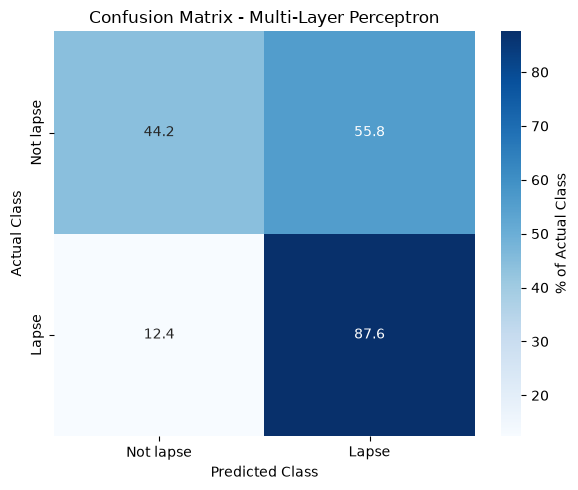

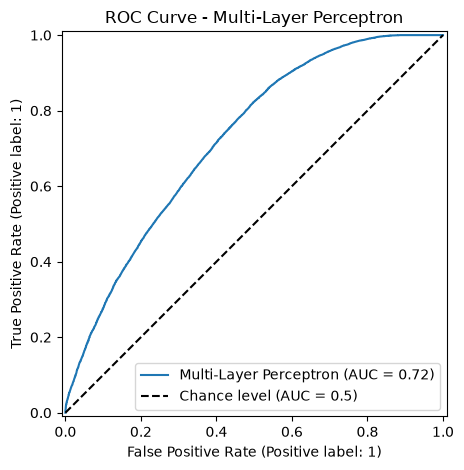

In [15]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "% of Actual Class"}
)
plt.title(f"Confusion Matrix - {MODEL_NAME}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

# Graph 2: ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob, name=MODEL_NAME, plot_chance_level=True)
plt.title(f"ROC Curve - {MODEL_NAME}")
plt.tight_layout()
plt.show()